# Real Sundarbans network vs. a hypothetical tree (18 Jan 2016)

*"Rivers are supposed to be trees. The Sundarbans aren't."* This notebook measures **how far from a tree** the real network is.

1. Load the image and extract the **cleaned RivGraph network**. This uses the Sundarbans-specific pruning in `sundarbans_rg.py`: RivGraph's stock `prune_network` crashes when the shoreline splits the scene into several estuary systems.
2. Build a **hypothetical tree** on the same channels. Outlets are the roots (parents), inlets are the leaves, and junctions sit in between.
3. Compare the two on **path lengths**, **independent cycles (and their sizes)** and **bridges** (`networkx.bridges`).

Kernel: *Python (rivgraph)*.

In [1]:
import numpy as np, pandas as pd, networkx as nx, matplotlib.pyplot as plt, geopandas as gpd, warnings
from matplotlib.lines import Line2D
from sundarbans_rg import extract_network
warnings.filterwarnings('ignore')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

net = extract_network('18th Jan 2016.tiff', 'example_2016')
rn, G, D = net['rn'], net['G'], net['D']
inlets, outlets = list(rn.nodes['inlets']), list(rn.nodes['outlets'])
print(f"raw RivGraph network: {net['n_raw_links']} links")
print(f"cleaned network: {G.number_of_nodes()} nodes, {G.number_of_edges()} links, {len(inlets)} inlets, {len(outlets)} outlets")
print('flow graph is acyclic (DAG):', nx.is_directed_acyclic_graph(D))

Warning 1: DeprecationWarning: 'Memory' driver is deprecated since GDAL 3.11. Use 'MEM' onwards. Further messages of this type will be suppressed.


raw RivGraph network: 927 links
cleaned network: 104 nodes, 121 links, 26 inlets, 9 outlets
flow graph is acyclic (DAG): True


## 1. The cleaned graph: on the image, and as a node–edge network

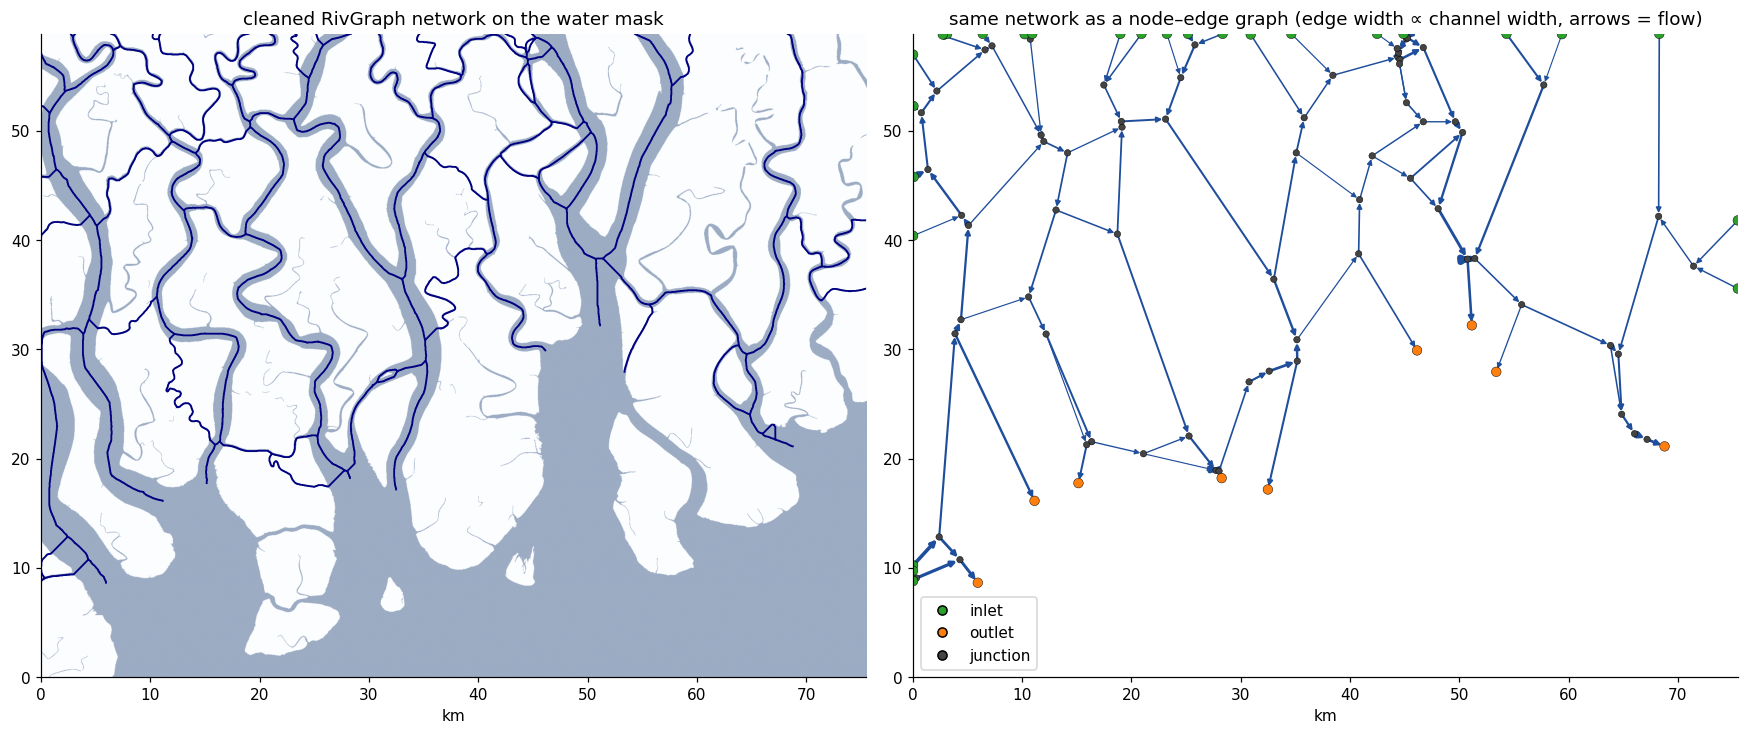

In [2]:
H, W = rn.imshape
T = net['transform']; px_x, px_y = T.a, -T.e
west, north = T.c, T.f
EXT = [0, W * px_x / 1e3, 0, H * px_y / 1e3]
km = lambda xy: ((xy[0] - west) / 1e3, (xy[1] - (north - H * px_y)) / 1e3)
POS = {n: km(d['pos']) for n, d in G.nodes(data=True)}
KIND_COL = {'inlet': '#2ca02c', 'outlet': '#ff7f0e', 'junction': '#444444'}

def draw_network(g, ax, edge_color='#1f4e9c', widths=True, node_size=18, edgelist=None):
    w = np.array([d['width'] for *_, d in g.edges(data=True)])
    lw = 0.6 + 3.5 * np.sqrt(w / w.max()) if widths else 1.2
    nx.draw_networkx_edges(g, POS, ax=ax,
                           edgelist=edgelist, width=lw if edgelist is None else 1.2, edge_color=edge_color,
                           **({'arrows': True, 'arrowsize': 7} if g.is_directed() else {}), node_size=node_size)
    nx.draw_networkx_nodes(g, POS, ax=ax, node_size=[node_size * (2.2 if g.nodes[n]['kind'] != 'junction' else 1) for n in g],
                           node_color=[KIND_COL[g.nodes[n]['kind']] for n in g], edgecolors='k', linewidths=0.3)
    ax.set_xlim(EXT[:2]); ax.set_ylim(EXT[2:]); ax.set_aspect('equal'); ax.tick_params(left=True, bottom=True, labelleft=True, labelbottom=True)

legend = [Line2D([], [], marker='o', ls='', color=c, mec='k', label=k) for k, c in KIND_COL.items()]

fig, axs = plt.subplots(1, 2, figsize=(16, 6.5))
axs[0].imshow(net['water'], cmap='Blues', alpha=0.4, extent=EXT)
for *_, d in G.edges(data=True):
    rr, cc = np.unravel_index(d['idx'], rn.imshape)
    axs[0].plot((cc + 0.5) * px_x / 1e3, EXT[3] - (rr + 0.5) * px_y / 1e3, color='navy', lw=1.2)
axs[0].set_title('cleaned RivGraph network on the water mask'); axs[0].set_xlim(EXT[:2]); axs[0].set_ylim(EXT[2:])
draw_network(D, axs[1])
axs[1].set_title('same network as a node–edge graph (edge width ∝ channel width, arrows = flow)')
axs[1].legend(handles=legend, loc='lower left')
for ax in axs: ax.set_xlabel('km')
plt.tight_layout(); plt.savefig('example_2016/network_node_edge.png', dpi=130); plt.show()

## 2. The hypothetical tree

**Rule ("widest-channel drainage tree"):** at every node, water leaves through its single **widest downstream channel**, the way a river follows its main channel.
Following that from every inlet gives one path per inlet. Paths merge but never split again, so their union is a **tree**:

* **roots / parents:** outlets (one tree per outlet that receives water; all of them hang off the sea),
* **leaves:** exactly the inlets,
* **internal nodes:** the junctions those paths pass through.

The tree uses only real channels from the image, so any difference from the real graph comes from the loops.
Channels that no inlet's main path uses are left out of the tree. The cell below reports how many.

In [3]:
def drainage_tree(D, inlets):
    # each node keeps its widest outgoing link
    keep = {}
    for n in D:
        out = list(D.out_edges(n, keys=True, data=True))
        if out:
            keep[n] = max(out, key=lambda e: e[3]['width'])
    Tr = nx.MultiDiGraph()
    for i in inlets:
        n = i
        while n in keep:
            u, v, k, d = keep[n]
            Tr.add_edge(u, v, key=k, **d)
            n = v
    for n in Tr:
        Tr.nodes[n].update(D.nodes[n])
    return Tr

TD = drainage_tree(D, inlets)                        # directed tree
TG = nx.MultiGraph(TD.to_undirected())               # undirected version
roots = [n for n in TD if TD.out_degree(n) == 0]
leaves = [n for n in TD if TD.in_degree(n) == 0]
print(f'tree: {TD.number_of_nodes()} nodes, {TD.number_of_edges()} links, {nx.number_connected_components(TG)} trees')
print(f'roots are all outlets: {set(roots) <= set(outlets)} ({len(roots)} of {len(outlets)} outlets receive water)')
print(f'leaves are exactly the inlets: {set(leaves) == set(inlets)}')
print(f'is a forest: {nx.is_forest(nx.Graph(TG))}')
tlen = sum(d['length'] for *_, d in TG.edges(data=True)); glen = sum(d['length'] for *_, d in G.edges(data=True))
print(f'real links not used by the tree: {G.number_of_edges() - TG.number_of_edges()} '
      f'({1 - TG.number_of_edges() / G.number_of_edges():.0%} of links, {1 - tlen / glen:.0%} of channel length)')

tree: 80 nodes, 76 links, 4 trees
roots are all outlets: True (4 of 9 outlets receive water)
leaves are exactly the inlets: True
is a forest: True
real links not used by the tree: 45 (37% of links, 41% of channel length)


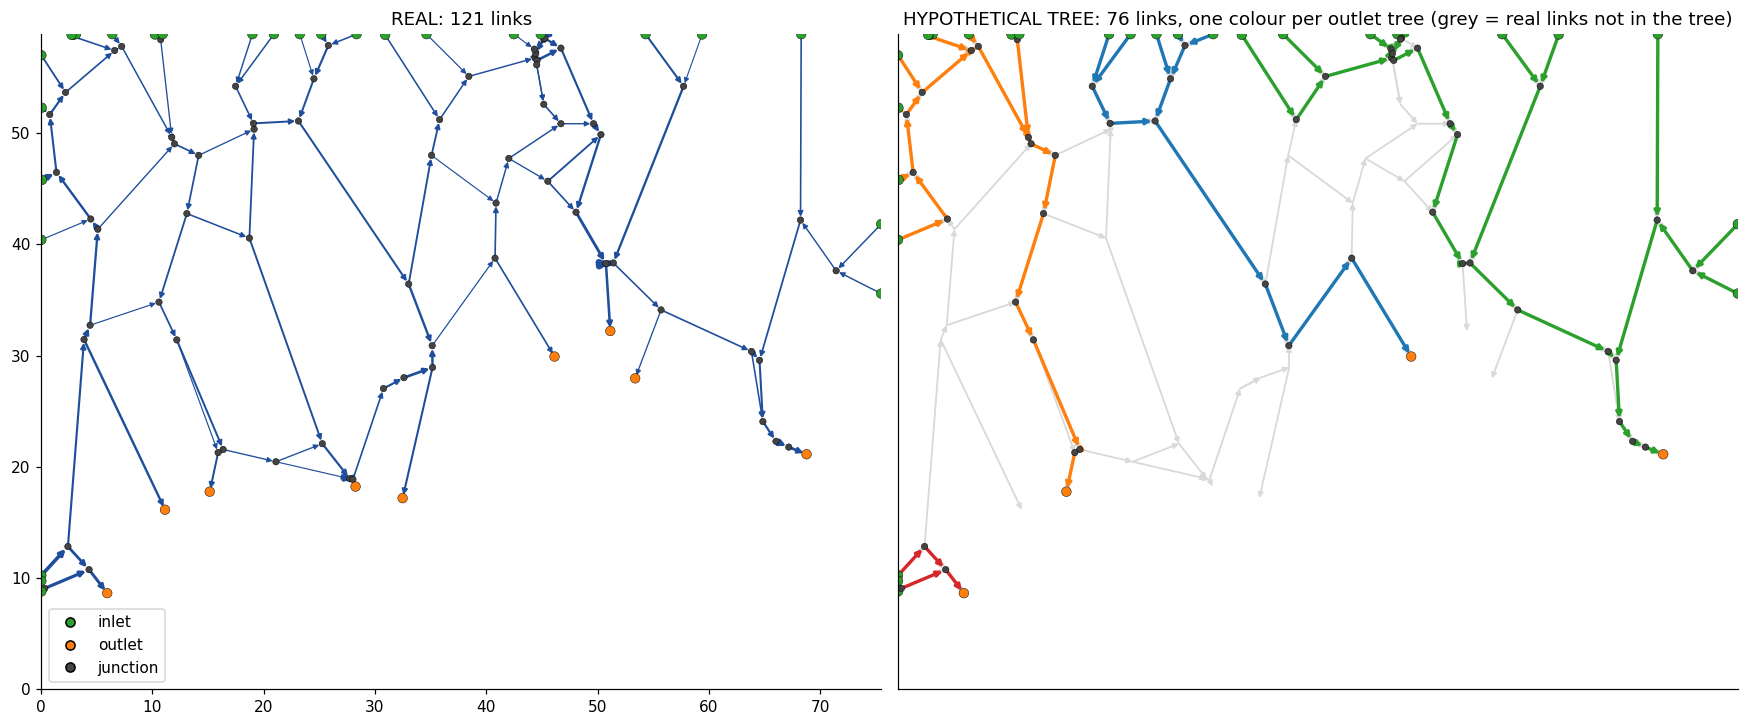

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(16, 6.5))
draw_network(D, axs[0]); axs[0].set_title(f'REAL: {G.number_of_edges()} links')
cmap = plt.get_cmap('tab10')
comp_of = {n: i for i, c in enumerate(nx.connected_components(nx.Graph(TG))) for n in c}
draw_network(D, axs[1], edge_color='0.85', widths=False, node_size=0)
for i, comp in enumerate(nx.connected_components(nx.Graph(TG))):
    sub = TD.subgraph(comp)
    nx.draw_networkx_edges(sub, POS, ax=axs[1], edge_color=[cmap(i % 10)], width=2.2, arrowsize=7, node_size=18)
nx.draw_networkx_nodes(TD, POS, ax=axs[1], node_size=[40 if TD.nodes[n]['kind'] != 'junction' else 18 for n in TD],
                       node_color=[KIND_COL[TD.nodes[n]['kind']] for n in TD], edgecolors='k', linewidths=0.3)
axs[1].set_title(f'HYPOTHETICAL TREE: {TG.number_of_edges()} links, one colour per outlet tree (grey = real links not in the tree)')
axs[0].legend(handles=legend, loc='lower left')
plt.tight_layout(); plt.savefig('example_2016/real_vs_tree.png', dpi=130); plt.show()

## 3. Comparison

`networkx` cycle and bridge functions need a **simple** graph, but the real network has parallel channels (two links between the same two nodes, around a small island).
Merging them would hide those loops, so each extra parallel link is split by a virtual mid-point node. Cycle sizes below are counted in **real links**.

In [5]:
def to_simple(g):
    S = nx.Graph()
    S.add_nodes_from(g.nodes(data=True))
    for u, v, k, d in g.edges(keys=True, data=True):
        a = dict(length=d['length'], width=d['width'], link=k)
        if u != v and not S.has_edge(u, v):
            S.add_edge(u, v, **a)
        else:                                             # parallel link or self-loop -> subdivide
            m1, m2 = ('virtual', k, 1), ('virtual', k, 2)
            half = {**a, 'length': d['length'] / 3}
            S.add_node(m1, kind='virtual'); S.add_node(m2, kind='virtual')
            S.add_edge(u, m1, **half); S.add_edge(m1, m2, **half); S.add_edge(m2, v, **half)
    return S

SG, ST = to_simple(G), to_simple(TG)

### 3a. Independent cycles and their sizes

**Independent cycles** = E − V + C (links − nodes + components). This is 0 for any tree, so it is the plainest measure of distance from a tree.
`nx.minimum_cycle_basis` (weighted by channel length) breaks the loops into their smallest independent rings, which are roughly the islands that the channels go around.

In [6]:
def cycles(S):
    out = []
    for nodes in nx.minimum_cycle_basis(S, weight='length'):
        sub = S.subgraph(nodes)
        links = {d['link'] for *_, d in sub.edges(data=True)}
        out.append(dict(nodes=nodes, n_links=len(links),
                        perimeter_km=sum(d['length'] for *_, d in sub.edges(data=True)) / 1e3))
    return pd.DataFrame(out)

def n_cycles(g):
    return g.number_of_edges() - g.number_of_nodes() + nx.number_connected_components(g)

cyc = cycles(SG)
print(f'independent cycles  real: {n_cycles(G)}   tree: {n_cycles(TG)}   (basis found {len(cyc)})')
cyc.sort_values('perimeter_km').drop(columns='nodes').describe().round(2)

independent cycles  real: 18   tree: 0   (basis found 18)


,n_links,perimeter_km
count,18.00,18.00
mean,5.22,32.66
std,3.19,27.64
min,2.00,3.47
25%,3.00,10.49
50%,4.50,23.69
75%,6.75,51.27
max,13.00,103.09


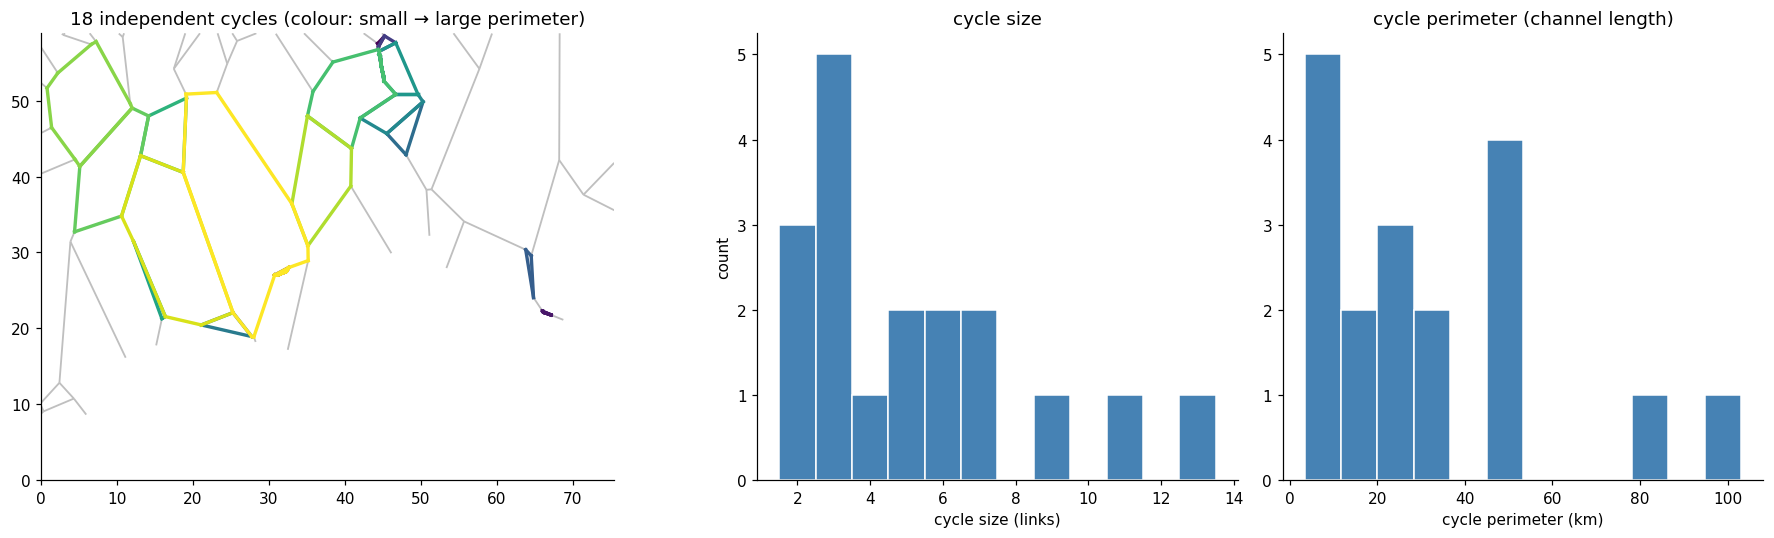

In [7]:
fig, axs = plt.subplots(1, 3, figsize=(17, 5), gridspec_kw={'width_ratios': [1.6, 1, 1]})
draw_network(G, axs[0], edge_color='0.75', widths=False, node_size=0)
cm = plt.get_cmap('viridis')
order = cyc.sort_values('perimeter_km').index
for rank, i in enumerate(order):
    sub = SG.subgraph(cyc.loc[i, 'nodes'])
    for u, v in sub.edges():
        if u in POS and v in POS:
            axs[0].plot(*zip(POS[u], POS[v]), color=cm(rank / max(len(cyc) - 1, 1)), lw=2.2)
        else:                                   # edge to a virtual node: draw the real parallel link's path
            k = sub[u][v]['link']; rr, cc = np.unravel_index(G.edges[[e for e in G.edges(keys=True) if e[2] == k][0]]['idx'], rn.imshape)
            axs[0].plot((cc + 0.5) * px_x / 1e3, EXT[3] - (rr + 0.5) * px_y / 1e3, color=cm(rank / max(len(cyc) - 1, 1)), lw=2.2)
axs[0].set_title(f'{len(cyc)} independent cycles (colour: small → large perimeter)')
axs[1].hist(cyc['n_links'], bins=np.arange(1.5, cyc['n_links'].max() + 1.5), color='steelblue', ec='w')
axs[1].set_xlabel('cycle size (links)'); axs[1].set_ylabel('count'); axs[1].set_title('cycle size')
axs[2].hist(cyc['perimeter_km'], bins=12, color='steelblue', ec='w')
axs[2].set_xlabel('cycle perimeter (km)'); axs[2].set_title('cycle perimeter (channel length)')
plt.tight_layout(); plt.savefig('example_2016/cycles.png', dpi=130); plt.show()

### 3b. Bridges

A **bridge** is a link whose removal disconnects the graph (`nx.bridges`). If it silts up or is cut off, everything beyond it is isolated.
In a tree **every link is a bridge**. In the real network, loops protect links. Links that lead to an inlet or outlet stub are always bridges, so we also count the **non-trivial bridges** (both ends are junctions).

In [8]:
def bridge_stats(S, g):
    br = list(nx.bridges(S))
    deg = dict(S.degree())
    nontriv = [(u, v) for u, v in br if deg[u] > 1 and deg[v] > 1]
    blen = sum(S[u][v]['length'] for u, v in br)
    return br, nontriv, dict(
        bridges=len(br), bridge_share_of_links=len(br) / g.number_of_edges(),
        bridge_share_of_length=blen / sum(d['length'] for *_, d in g.edges(data=True)),
        nontrivial_bridges=len(nontriv))

brG, ntG, bsG = bridge_stats(SG, G)
brT, ntT, bsT = bridge_stats(ST, TG)
pd.DataFrame({'real': bsG, 'tree': bsT}).round(3)

,real,tree
bridges,52.000,76.0
bridge_share_of_links,0.430,1.0
bridge_share_of_length,0.446,1.0
nontrivial_bridges,17.000,46.0


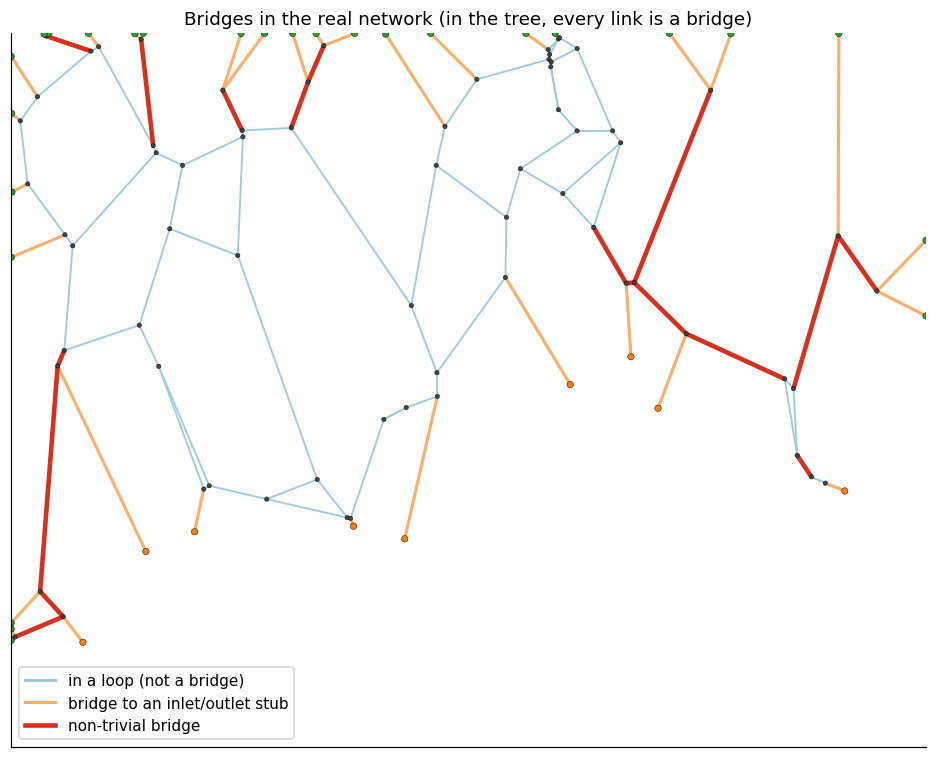

In [9]:
fig, ax = plt.subplots(figsize=(10, 7))
draw_network(G, ax, edge_color='#9ecae1', widths=False, node_size=8)
nx.draw_networkx_edges(nx.Graph(SG), POS, edgelist=[e for e in brG if e not in ntG], ax=ax, edge_color='#fdae6b', width=2)
nx.draw_networkx_edges(nx.Graph(SG), POS, edgelist=ntG, ax=ax, edge_color='#d7301f', width=3)
ax.legend(handles=[Line2D([], [], color='#9ecae1', lw=2, label='in a loop (not a bridge)'),
                   Line2D([], [], color='#fdae6b', lw=2, label='bridge to an inlet/outlet stub'),
                   Line2D([], [], color='#d7301f', lw=3, label='non-trivial bridge')], loc='lower left')
ax.set_title('Bridges in the real network (in the tree, every link is a bridge)')
plt.tight_layout(); plt.savefig('example_2016/bridges.png', dpi=130); plt.show()

### 3c. Path lengths from each inlet to the sea

For every inlet:
* **tree path:** the single path through the tree (always the widest channel).
* **real shortest path:** the shortest *downstream* path in the real network, to whichever outlet is closest.
* **number of alternative paths:** distinct downstream routes to any outlet (Tejedor's *N<sub>ap</sub>*, counted by dynamic programming on the DAG). This is 1 in a tree.
* **outlets reachable:** 1 in a tree.

Ratio **tree / real ≥ 1** shows how much the loops shorten the trip to the sea.

In [10]:
def shortest_to_sea(Dg, outlets):
    R = nx.DiGraph()
    for u, v, d in Dg.edges(data=True):          # reversed, keep the shortest of parallel links
        if not R.has_edge(v, u) or d['length'] < R[v][u]['length']:
            R.add_edge(v, u, length=d['length'])
    dist_m = nx.multi_source_dijkstra_path_length(R, set(outlets) & set(R), weight='length')
    dist_h = nx.multi_source_dijkstra_path_length(R, set(outlets) & set(R), weight=None)
    return dist_m, dist_h

def n_paths(Dg, outlets):
    npth = {}
    for n in reversed(list(nx.topological_sort(Dg))):
        npth[n] = 1 if n in outlets else sum(npth[v] for _, v in Dg.out_edges(n))   # parallel links counted separately
    return npth

dmG, dhG = shortest_to_sea(D, outlets)
dmT, dhT = shortest_to_sea(TD, outlets)
npG = n_paths(D, set(outlets))
paths = pd.DataFrame({
    'real_shortest_km': {i: dmG[i] / 1e3 for i in inlets},
    'tree_km': {i: dmT[i] / 1e3 for i in inlets},
    'real_shortest_hops': {i: dhG[i] for i in inlets},
    'tree_hops': {i: dhT[i] for i in inlets},
    'alt_paths_real': {i: npG[i] for i in inlets},
    'outlets_reachable_real': {i: len(nx.descendants(D, i) & set(outlets)) for i in inlets},
})
paths['tree/real length'] = paths['tree_km'] / paths['real_shortest_km']
paths.index.name = 'inlet'
paths.round(2).sort_values('tree/real length', ascending=False)

,real_shortest_km,tree_km,real_shortest_hops,tree_hops,alt_paths_real,outlets_reachable_real,tree/real length
inlet,,,,,,,
10,32.27,62.45,7,18,42,3,1.94
9,35.66,63.34,10,17,18,3,1.78
8,50.75,78.43,9,16,18,3,1.55
14,38.07,57.09,4,9,5,2,1.50
11,38.47,57.49,4,9,5,2,1.49
16,62.45,90.13,10,17,18,3,1.44
12,49.23,50.58,6,6,2,1,1.03
59,43.78,45.13,7,7,2,1,1.03
68,43.49,44.84,7,7,2,1,1.03


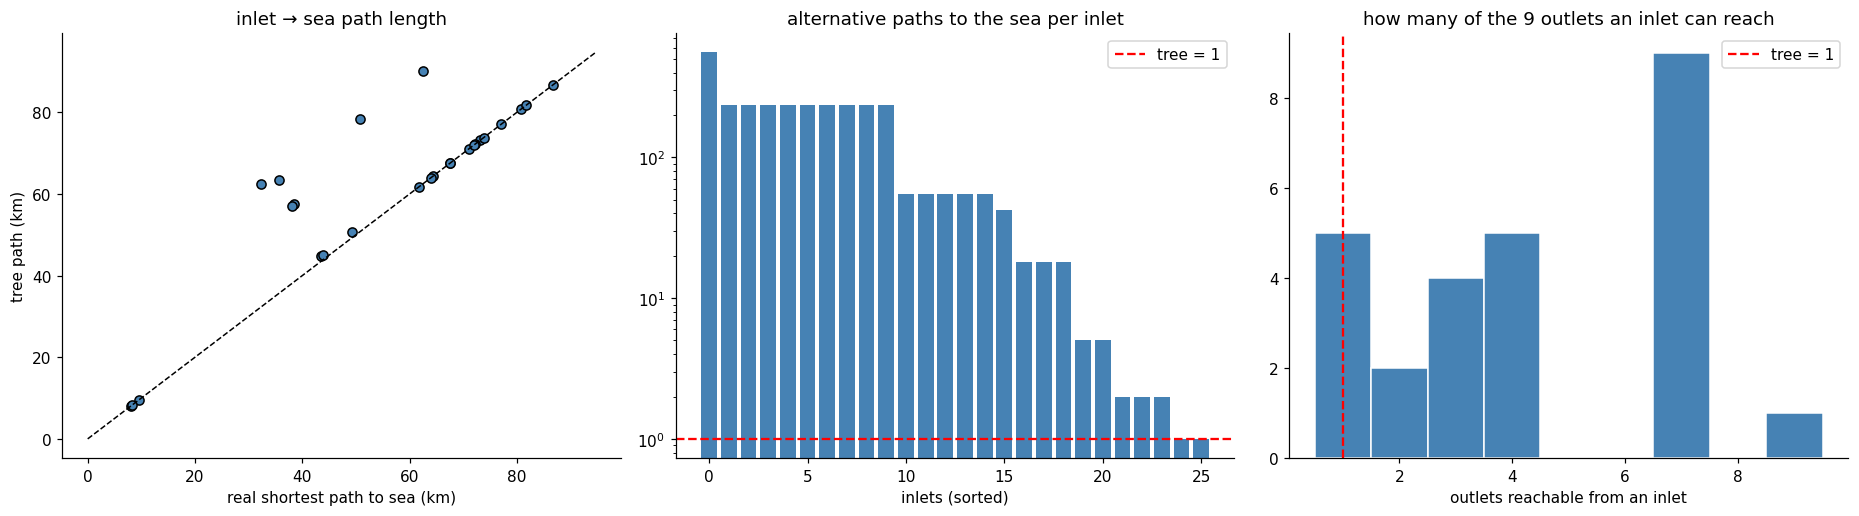

In [11]:
fig, axs = plt.subplots(1, 3, figsize=(17, 4.8))
ax = axs[0]
ax.scatter(paths['real_shortest_km'], paths['tree_km'], c='steelblue', ec='k')
m = paths[['real_shortest_km', 'tree_km']].values.max() * 1.05
ax.plot([0, m], [0, m], 'k--', lw=1); ax.set_xlabel('real shortest path to sea (km)'); ax.set_ylabel('tree path (km)')
ax.set_title('inlet → sea path length')
axs[1].bar(range(len(paths)), paths['alt_paths_real'].sort_values(ascending=False), color='steelblue')
axs[1].axhline(1, color='r', ls='--', label='tree = 1'); axs[1].set_yscale('log'); axs[1].legend()
axs[1].set_xlabel('inlets (sorted)'); axs[1].set_title('alternative paths to the sea per inlet')
axs[2].hist(paths['outlets_reachable_real'], bins=np.arange(0.5, len(outlets) + 1.5), color='steelblue', ec='w')
axs[2].axvline(1, color='r', ls='--', label='tree = 1'); axs[2].legend()
axs[2].set_xlabel('outlets reachable from an inlet'); axs[2].set_title(f'how many of the {len(outlets)} outlets an inlet can reach')
plt.tight_layout(); plt.savefig('example_2016/path_lengths.png', dpi=130); plt.show()

### 3d. Side-by-side summary

In [12]:
def char_path(g):
    S = nx.Graph(g)
    c = S.subgraph(max(nx.connected_components(S), key=len))
    return nx.average_shortest_path_length(c), nx.diameter(c)

cpG, diaG = char_path(G); cpT, diaT = char_path(TG)
summary = pd.DataFrame({
    'real': {
        'nodes': G.number_of_nodes(), 'links': G.number_of_edges(), 'connected pieces': nx.number_connected_components(G),
        'channel length (km)': glen / 1e3,
        'independent cycles (E−V+C)': n_cycles(G),
        'mean cycle size (links)': cyc['n_links'].mean(), 'max cycle size (links)': cyc['n_links'].max(),
        'mean cycle perimeter (km)': cyc['perimeter_km'].mean(),
        'bridges': bsG['bridges'], 'bridge share of links': bsG['bridge_share_of_links'],
        'bridge share of length': bsG['bridge_share_of_length'], 'non-trivial bridges': bsG['nontrivial_bridges'],
        'mean inlet→sea path (km)': paths['real_shortest_km'].mean(), 'mean inlet→sea path (links)': paths['real_shortest_hops'].mean(),
        'mean alternative paths per inlet': paths['alt_paths_real'].mean(), 'max alternative paths': paths['alt_paths_real'].max(),
        'mean outlets reachable per inlet': paths['outlets_reachable_real'].mean(),
        'characteristic path length (links, largest piece)': cpG, 'diameter (links, largest piece)': diaG,
    },
    'tree': {
        'nodes': TG.number_of_nodes(), 'links': TG.number_of_edges(), 'connected pieces': nx.number_connected_components(TG),
        'channel length (km)': tlen / 1e3,
        'independent cycles (E−V+C)': n_cycles(TG),
        'mean cycle size (links)': np.nan, 'max cycle size (links)': np.nan, 'mean cycle perimeter (km)': np.nan,
        'bridges': bsT['bridges'], 'bridge share of links': bsT['bridge_share_of_links'],
        'bridge share of length': bsT['bridge_share_of_length'], 'non-trivial bridges': bsT['nontrivial_bridges'],
        'mean inlet→sea path (km)': paths['tree_km'].mean(), 'mean inlet→sea path (links)': paths['tree_hops'].mean(),
        'mean alternative paths per inlet': 1, 'max alternative paths': 1, 'mean outlets reachable per inlet': 1,
        'characteristic path length (links, largest piece)': cpT, 'diameter (links, largest piece)': diaT,
    }})
summary.to_csv('example_2016/real_vs_tree_2016-01-18.csv')
summary.style.format('{:.3g}', na_rep='—')

,real,tree
nodes,104,80
links,121,76
connected pieces,1,4
channel length (km),758,445
independent cycles (E−V+C),18,0
mean cycle size (links),5.22,—
max cycle size (links),13,—
mean cycle perimeter (km),32.7,—
bridges,52,76
bridge share of links,0.43,1


## 4. What the comparison shows (filled in from this run)

| | real | tree |
|---|---|---|
| links / channel length | 121 / 758 km | 76 / 445 km |
| independent cycles | **18** | 0 |
| cycle size | 2–13 links (median 4.5), perimeters 3–103 km | — |
| bridges | **43%** of links (17 non-trivial) | 100% |
| mean inlet → sea path | 55 km, 7.9 links | 61 km, 9.9 links |
| alternative paths per inlet | mean 118, max 556 | 1 |
| outlets reachable per inlet | mean 4.3 of 9 | 1 |

* **Not a tree.** There are 18 independent loops, with a wide spread of sizes: small 2–3-link rings around single islands, and big 50–100 km circuits that join neighbouring estuaries. The big loops are in the west-centre. The east is almost tree-like.
* **Loops buy redundancy, not shorter routes.** For 20 of 26 inlets the widest channel is already the shortest way to the sea (ratio = 1). The north-west inlets gain the most: loops cut their trip by up to ~50% (tree path 1.5–1.9× longer).
  The real gain is choice. An inlet has on average ~120 downstream routes and can reach ~4 outlets, against exactly one of each in the tree.
* **The tree starves outlets.** If water only followed the widest channel, just 4 of 9 outlets would receive any. The other 5 are fed only through loops and side channels, about 40% of the channel length.
* **Bridges are where the network is fragile.** 57% of links sit in a loop and can be lost without disconnecting anything. The 17 non-trivial bridges (red in the bridges map) are single points of failure, mostly in the east and on the inlet/outlet branches. In a tree every link is one.
* Characteristic path length and diameter come out *lower* for the tree only because its largest piece is smaller (it splits into 4 trees). Compare them between dates, not between real and tree.

**For the time series:** track independent cycles, the cycle-size distribution, the bridge share and the alternative paths per inlet. A network that is silting up should lose its small loops first, and its bridge share should rise.